In [1]:
import sys, os
src_path = "../../"
sys.path.append(src_path) #arXiv:1809.01876

import numpy as np
from src_scalar.foresee import Foresee, Utility, Model
from matplotlib import pyplot as plt

import numpy as np
import os
from matplotlib import pyplot as plt
import math
import random
from skhep.math.vectors import LorentzVector, Vector3D
from scipy import interpolate
from matplotlib import gridspec
import os, inspect
from matplotlib.colors import LogNorm

sys.path.insert(1, os.path.join(os.path.dirname(os.path.realpath(
                inspect.getfile(inspect.currentframe()))), "/home/souvik/codes/darkcast_chiral/"))
import darkcast_scalar as darkcast  

In [46]:
foresee = Foresee()
energy = "100"
unit = "TeV"
modelname = "DarkHiggs"
model = Model(modelname, path="/home/souvik/codes/foresee-main/Models/DarkHiggs/", mzp = 100, gBL = 0.01)

21000 21000


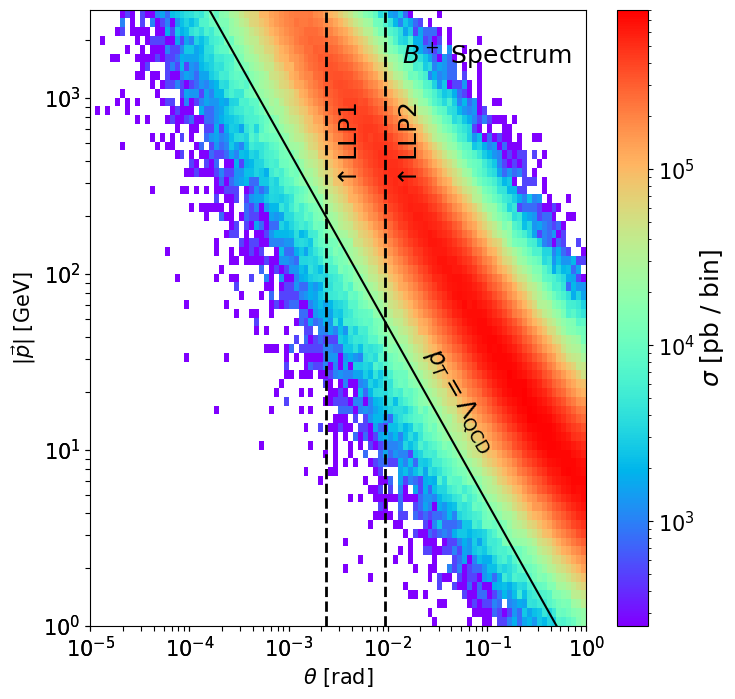

21000 21000


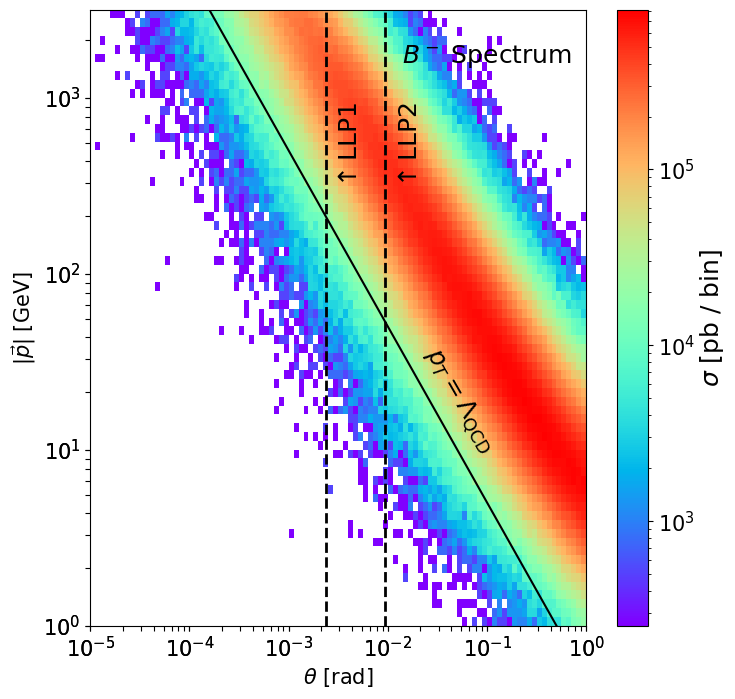

21000 21000


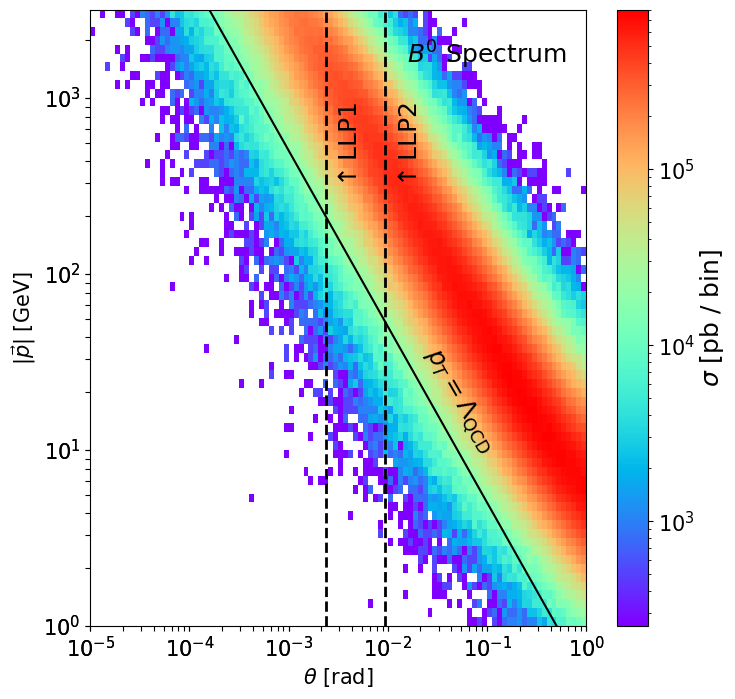

21000 21000


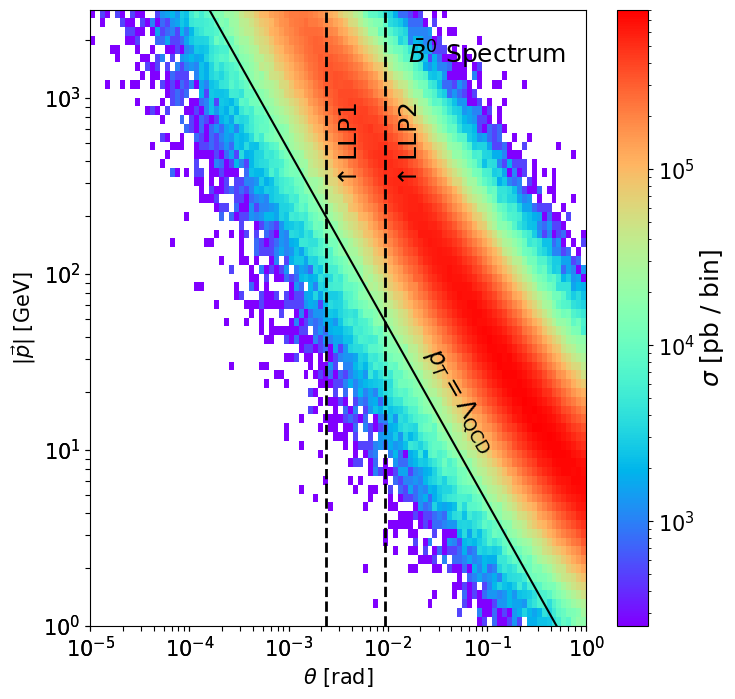

In [57]:
path = "/home/souvik/codes/foresee-main/files/hadrons/100TeV/Pythia8/"
pids = ["511", "-511", "521", "-521"]
masses = {"511": 5.27961, "-511": 5.27961, "521": 5.27929, "-521": 5.27929}
names = {"511": r"$B^+$", "-511": r"$B^-$", "521": r"$B^0$", "-521": r"$\bar{B}^0$"}
for pid in pids:
    file = path+"Pythia8_100TeV_"+pid+".txt"
    data = np.genfromtxt(file)
    ps , ws = foresee.convert_list_to_momenta(file,masses[pid], filetype="txt",luminosity=3000, nsample=1,preselectioncut=None, 
                                      nocuts=False, mincount=0, extend_to_low_pt_scale=None)
    foresee.convert_to_hist_list(ps,ws,luminosity=1/1000, do_plot=True, filename=None, cmap="rainbow",
                         do_return=False, prange=[[-5, 0, 100],[0, 3.5, 70]], vmin=None, vmax=None)
    
    plt.gca()
    plt.axvline(x=np.log10(10*np.sqrt(2)/1500), color='black', linestyle='--', linewidth=2)
    plt.axvline(x=np.log10(2.5*np.sqrt(2)/1500), color='black', linestyle='--', linewidth=2)
    plt.text(-2.5, 2.5, r"$\uparrow$LLP1", fontsize=18, rotation=90)
    plt.text(-1.9, 2.5, r"$\uparrow$LLP2", fontsize=18, rotation=90)

    ts = [p.pt/p.p for p in ps]
    x = [np.log10(t) for t in ts]
    y = [np.log10(0.5)-i for i in x]
    print(len(ps), len(ws))
    plt.plot(x, y, color="black")
    
    plt.title(names[pid]+" Spectrum", y=0.9, x=0.8)
    plt.text(-1.7, 1, r"$p_T=\Lambda_\text{QCD}$", fontsize=18, rotation=-60)
    
    plt.xlabel(r"$\theta$ [rad]")
    plt.ylabel(r"$|\vec{p}|$ [GeV]")
    plt.savefig("./"+pid+".png")
    plt.show()
    # foresee.get_spectrumplot(luminosity=3000, pid=pid, particle=r"$\Z'$--", generator="EPOSLHC", 
    #                      energy="14", prange=[[-6, 0, 120],[ 0, 5, 50]], vmin=0.5e12, vmax=0.5e16, mincount=0)

In [4]:
model.add_production_2bodydecay(
    pid0 = "511",
    pid1 = "130",
    br = "5.6 * coupling**2 * (1.-(mass/self.masses('pid0'))**2)**2",
    generator = 'Pythia8',
    energy = energy,
    nsample = 50,
)

model.add_production_2bodydecay(
    pid0 = "-511",
    pid1 = "130",
    br = "5.6 * coupling**2 * (1.-(mass/self.masses('pid0'))**2)**2",
    generator = 'Pythia8',
    energy = energy,
    nsample = 50,
)

model.add_production_2bodydecay(
    pid0 = "521",
    pid1 = "321",
    br = "5.6 * coupling**2 * (1.-(mass/self.masses('pid0'))**2)**2",
    generator = 'Pythia8',
    energy = energy,
    nsample = 50,
)

model.add_production_2bodydecay(
    pid0 = "-521",
    pid1 = "321",
    br = "5.6 * coupling**2 * (1.-(mass/self.masses('pid0'))**2)**2",
    generator = 'Pythia8',
    energy = energy,
    nsample = 50,
)

In [5]:
model.add_production_2bodydecay(
    label= "511*",
    pid0 = "511",
    pid1 = "313",
    br = "5.6 * coupling**2 * (1.-(mass/self.masses('pid0'))**2)**2",
    generator = 'Pythia8',
    energy = energy,
    nsample = 50,
)

model.add_production_2bodydecay(
    label= "-511*",
    pid0 = "-511",
    pid1 = "-313",
    br = "5.6 * coupling**2 * (1.-(mass/self.masses('pid0'))**2)**2",
    generator = 'Pythia8',
    energy = energy,
    nsample = 50,
)

model.add_production_2bodydecay(
    label= "521*",
    pid0 = "521",
    pid1 = "323",
    br = "5.6 * coupling**2 * (1.-(mass/self.masses('pid0'))**2)**2",
    generator = 'Pythia8',
    energy = energy,
    nsample = 50,
)

model.add_production_2bodydecay(
    label= "-521*",
    pid0 = "-521",
    pid1 = "-323",
    br = "5.6 * coupling**2 * (1.-(mass/self.masses('pid0'))**2)**2",
    generator = 'Pythia8',
    energy = energy,
    nsample = 50,
)

In [6]:
model.add_production_3bodydecay(
    label= "511_di",
    pid0 = "511",
    pid1 = "130",
    pid2 = "0",
    br = "6.76e-5*(self.model.lambda_mix(coupling, mass))**2*(self.masses('5')/4.5)**3*np.sqrt(1-4*mass**2/q**2)*(1-q**2/self.masses('5')**2)**2",
    generator = 'Pythia8',
    energy = energy,
    nsample = 50,
    scaling = 0, 
)

model.add_production_3bodydecay(
    label= "-511_di",
    pid0 = "-511",
    pid1 = "130",
    pid2 = "0",
    br = "6.76e-5*(self.model.lambda_mix(coupling, mass))**2*(self.masses('5')/4.5)**3*np.sqrt(1-4*mass**2/q**2)*(1-q**2/self.masses('5')**2)**2",
    generator = 'Pythia8',
    energy = energy,
    nsample = 50,
    scaling = 0, 
)

model.add_production_3bodydecay(
    label= "521_di",
    pid0 = "521",
    pid1 = "321",
    pid2 = "0",
    br = "6.76e-5*(self.model.lambda_mix(coupling, mass))**2*(self.masses('5')/4.5)**3*np.sqrt(1-4*mass**2/q**2)*(1-q**2/self.masses('5')**2)**2",
    generator = 'Pythia8',
    energy = energy,
    nsample = 50,
    scaling = 0, 
)

model.add_production_3bodydecay(
    label= "-521_di",
    pid0 = "-521",
    pid1 = "321",
    pid2 = "0",
    br = "6.76e-5*(self.model.lambda_mix(coupling, mass))**2*(self.masses('5')/4.5)**3*np.sqrt(1-4*mass**2/q**2)*(1-q**2/self.masses('5')**2)**2",
    generator = 'Pythia8',
    energy = energy,
    nsample = 50,
    scaling = 0, 
)

In [7]:
model.add_production_3bodydecay(
    label= "511_di",
    pid0 = "511",
    pid1 = "313",
    pid2 = "0",
    br = "6.76e-5*(self.model.lambda_mix(coupling, mass))**2*(self.masses('5')/4.5)**3*np.sqrt(1-4*mass**2/q**2)*(1-q**2/self.masses('5')**2)**2",
    generator = 'Pythia8',
    energy = energy,
    nsample = 50,
    scaling = 0, 
)

model.add_production_3bodydecay(
    label= "-511_di",
    pid0 = "-511",
    pid1 = "313",
    pid2 = "0",
    br = "6.76e-5*(self.model.lambda_mix(coupling, mass))**2*(self.masses('5')/4.5)**3*np.sqrt(1-4*mass**2/q**2)*(1-q**2/self.masses('5')**2)**2",
    generator = 'Pythia8',
    energy = energy,
    nsample = 50,
    scaling = 0, 
)

model.add_production_3bodydecay(
    label= "521_di",
    pid0 = "521",
    pid1 = "321",
    pid2 = "0",
    br = "6.76e-5*(self.model.lambda_mix(coupling, mass))**2*(self.masses('5')/4.5)**3*np.sqrt(1-4*mass**2/q**2)*(1-q**2/self.masses('5')**2)**2",
    generator = 'Pythia8',
    energy = energy,
    nsample = 50,
    scaling = 0, 
)

model.add_production_3bodydecay(
    label= "-521_di",
    pid0 = "-521",
    pid1 = "321",
    pid2 = "0",
    br = "6.76e-5*(self.model.lambda_mix(coupling, mass))**2*(self.masses('5')/4.5)**3*np.sqrt(1-4*mass**2/q**2)*(1-q**2/self.masses('5')**2)**2",
    generator = 'Pythia8',
    energy = energy,
    nsample = 50,
    scaling = 0, 
)

In [8]:
foresee.set_model(model=model)

In [9]:
# mass = 0.1
# model1 = {-2: "U1_X_2n", 2: "U1_X_2p"}
# xHs = [-2, 2]
# for xH in xHs:
#     foresee.get_llp_spectrum(mass=mass, coupling=1, luminosity=1/1000, mincount=0, cmap="rainbow",
#                                 do_plot=True, stat_cuts=None, save_file=False, prange=[[-5, 0, 100],[0, 3.5, 70]])
#         # r = foresee.ratio(mass, model1[xH], "B-L_boson", key, 1/3, 1/3, 1/3)
#         # for w,p in zip(ws, ps):
#         #     Ps.append(p)
#         #     Ws.append(w*r)
        
#     # foresee.convert_to_hist_list(Ps,Ws,luminosity=1/1000, do_plot=True, filename=None, cmap="rainbow",
#     #                      do_return=False, prange=[[-5, 0, 100],[0, 3.5, 70]], vmin=None, vmax=None)
    
#     plt.axvline(np.log(1/630), color='black', linestyle='--', linewidth=4)

#     plt.title(r"$M_{Z'}=$"+str(mass)+" GeV \n $x_H=$"+str(xH), y=0.9, x=0.8)

#     plt.gca()
#     plt.axvline(x=np.log10(1/630), color='black', linestyle='--', linewidth=2)

#     ts = 10**np.linspace(-5, 0, 100)
#     x = [np.log10(t) for t in ts]
#     y = [np.log10(0.5)-i for i in x]
#     plt.plot(x, y, color="black")
#     plt.text(-2.7, 0.5, r"$\uparrow$FASER2", fontsize=18, rotation=90)
#     plt.text(-1.8, 1, r"$p_T=\Lambda_\text{QCD}$", fontsize=18, rotation=-60)
#     plt.xlabel(r"$\theta_{Z^\prime}$ [rad]")
#     plt.ylabel(r"p$_{Z^\prime}$ [GeV]")
#     plt.savefig(r"/home/souvik/codes/FORESEE_fig/spectrum/Zp_"+str(xH)+".png")


In [10]:
def list_to_momenta(list_logth, list_logp, list_xs, mass, luminosity=3000, nsample=1):

    particles, weights = [], []
    for logth,logp,xs in zip(list_logth,list_logp, list_xs):

        # if nocuts==False and
        # if xs < mincount/(luminosity*1000): continue
        p  = 10.**logp
        th = 10.**logth
        pt = p * np.sin(th)

        for n in range(nsample):
            phi= random.uniform(-np.pi,np.pi)
            fth = 10**np.random.uniform(-0.025, 0.025, 1)[0]
            fp  = 10**np.random.uniform(-0.025, 0.025, 1)[0]

            th_sm=th*fth
            p_sm=p*fp

            en = np.sqrt(p_sm**2+mass**2)
            pz = p_sm*np.cos(th_sm)
            pt = p_sm*np.sin(th_sm)
            px = pt*np.cos(phi)
            py = pt*np.sin(phi)
            part=LorentzVector(px,py,pz,en)

            particles.append(part)
            weights.append(xs/float(nsample))

    return particles,weights

In [11]:
foresee.set_detector(
    distance=1500, 
    selection="abs(x.x)<10 and abs(x.y)<10", 
    length=400, unit="TeV",
    luminosity=30000, name="U1_X"
)

380.4261024226984


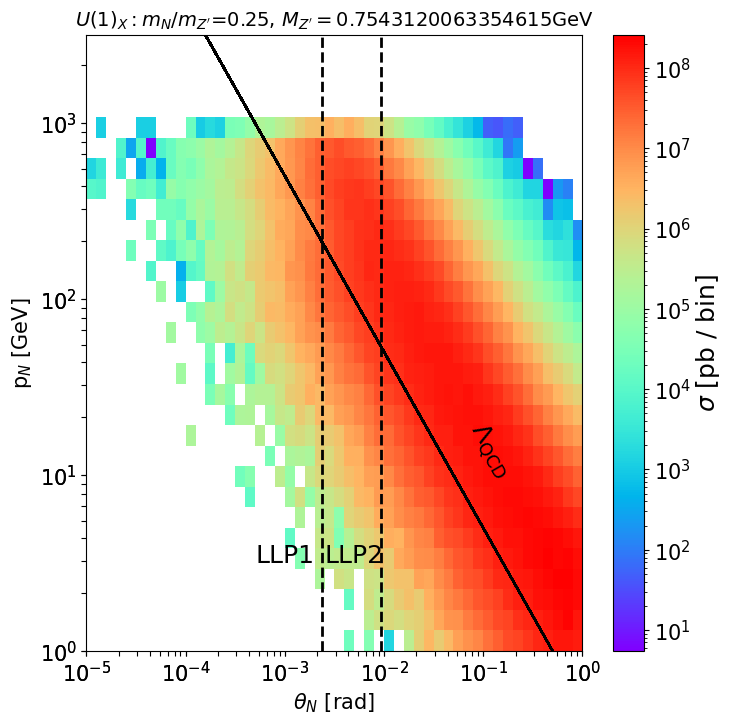

769.0372017537509


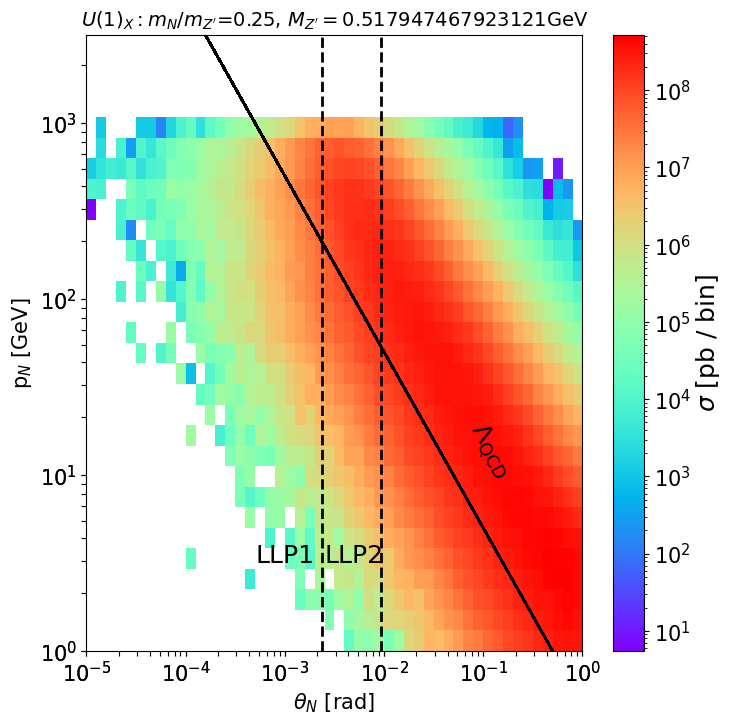

380.4261024226984


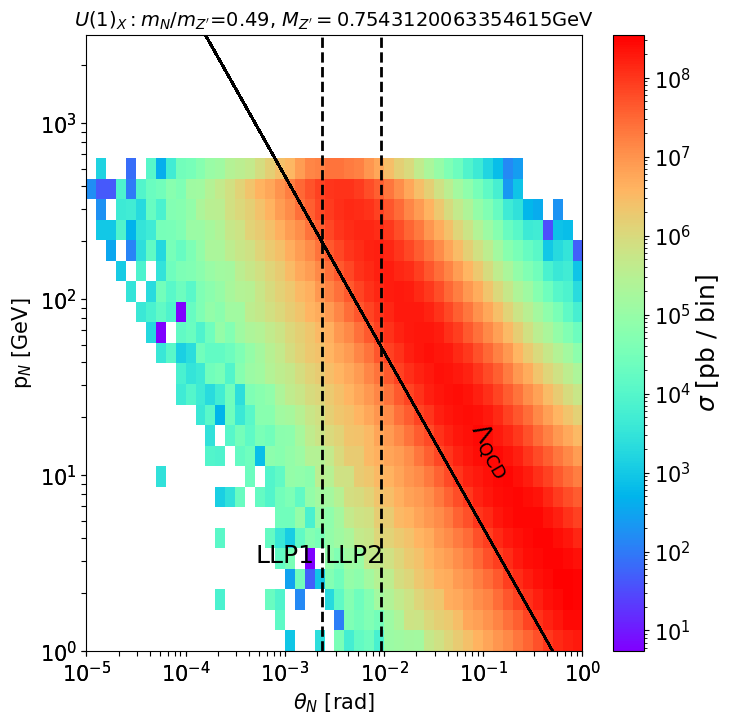

769.0372017537509


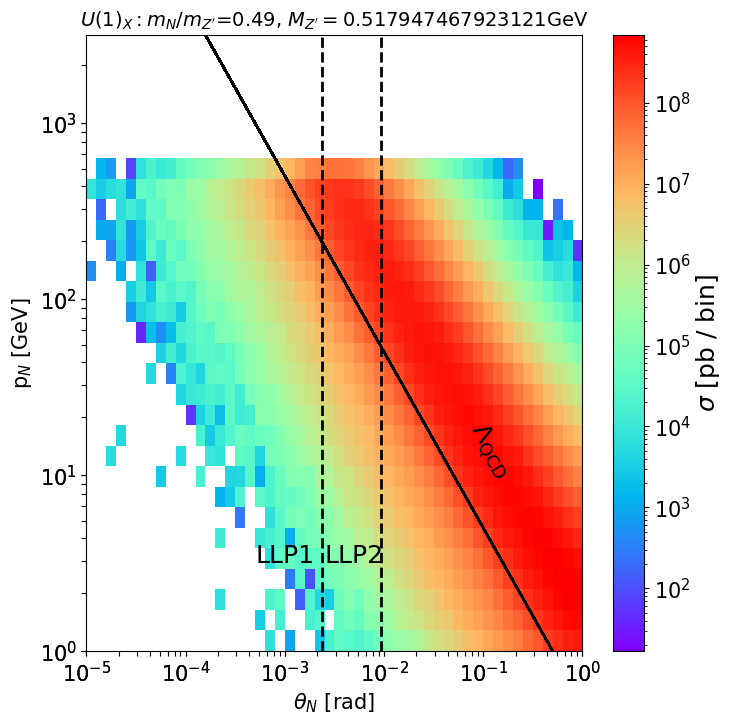

In [23]:
masses_all = np.logspace(-2, 0, 50)
masses = [masses_all[-4], masses_all[-8]]
mNs = [0.25, 0.49]

for mN in mNs:
    name = "U1_X"
    modelD = darkcast.Model(name, Y1=mN, Y2=1000, Y3=1000, mZ=100)
    pNs, wNs = [], []
        
    # Calculate branching fraction once per mass
    # bfrac_val = modelD.bfrac("Ne_Ne", mass, g=0.01, xH=0)
    for mass in masses:   
        for key in model.production.keys():
            dirname = "/home/souvik/codes/foresee-main/Models/DarkHiggs/model/LLP_spectra/"
            filename = f"{dirname}{energy}{unit}_{key}_{model.production[key]['type']}_m_{mass}.npy"
            p1s = foresee.decay_in_restframe_2body(1, mass, mass*mN, mass*mN, 1)[0]
            
            try:
                particles_llp, weights_llp = foresee.convert_list_to_momenta(
                    filename=filename, mass=mass, filetype="npy",
                    luminosity=1, nsample=5, preselectioncut=None
                )
            except Exception:
                print(f"Warning: file {filename} not found")
                continue

            for p, w in zip(particles_llp, weights_llp):
                if w == 0: 
                    continue
                # pNs.append(p)
                # wNs.append(w)
                for p1 in p1s:
                    p1lab = p1.boost(-1. * p.boostvector)
                    pNs.append(p1lab)
                    wNs.append(w)
                    
                    p2lab = p - p1lab
                    pNs.append(p2lab)
                    wNs.append(w)
        print(sum(wNs)/1e8)
        # 1. Extract 1D kinematic variables
        x_phi = []
        y_mag = []
        clean_weights = []
        for p, w in zip(pNs, wNs):
            if w > 0:
                phi = np.arccos(p.pz/ p.p) 
                mag = p.p 
                x_phi.append(phi)
                y_mag.append(mag)
                clean_weights.append(w)

        # 2. Guard against empty datasets
        if len(clean_weights) == 0 or sum(clean_weights) == 0:
            print(f"Skipping plot for mN={mN}, mass={mass}: No non-zero events generated.")
            continue


        foresee.convert_to_hist_list(pNs,wNs,luminosity=1/1000, do_plot=True, filename=None, cmap="rainbow",
                             do_return=False, prange=[[-5, 0, 50],[0, 3.5, 30]], vmin=None, vmax=None)

        plt.gca()
        plt.axvline(x=np.log10(10*np.sqrt(2)/1500), color='black', linestyle='--', linewidth=2)
        plt.axvline(x=np.log10(2.5*np.sqrt(2)/1500), color='black', linestyle='--', linewidth=2)

        ts = [p.pt/p.p for p in pNs]
        x = [np.log10(t) for t in ts]
        y = [np.log10(0.5)-i for i in x]
        plt.plot(x, y, color="black")
        plt.text(-3.3, 0.5, "LLP1", fontsize=18)
        plt.text(-2.6, 0.5, "LLP2", fontsize=18)
        plt.text(-1.2, 1, r"$\Lambda_\text{QCD}$", fontsize=18, rotation=-60)

        
        plt.xlabel(r"$\theta_{N}$ [rad]")
        plt.ylabel(r"p$_{N}$ [GeV]")
        
        plt.title(r"$U(1)_X: m_N/m_{Z'}$="+str(mN)+", $M_{Z'}=$"+str(mass)+"GeV", fontsize=14)
        plt.savefig("./"+str(mN)+"_"+str(mass)+"GeV.png")

        plt.show()

8.733238353707456e-08


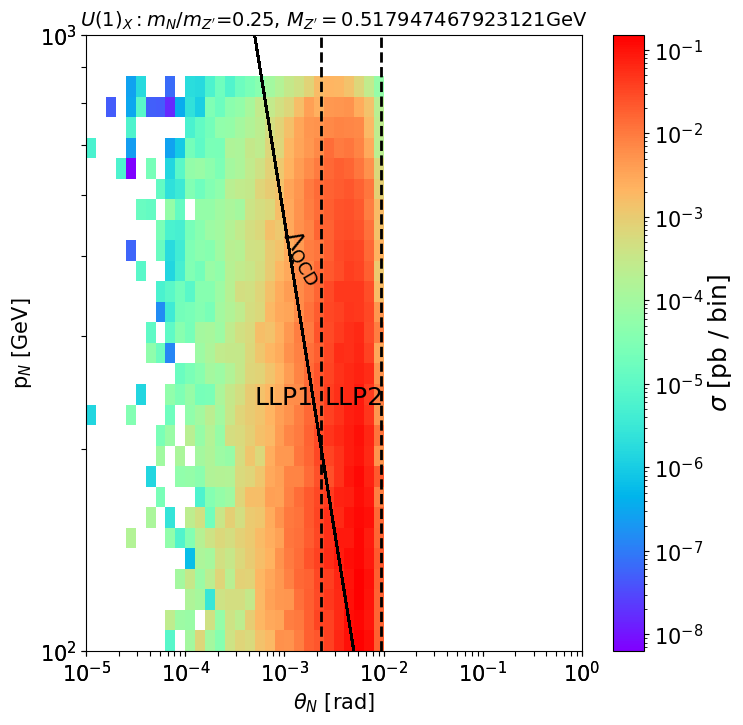

8.12317890515603e-06


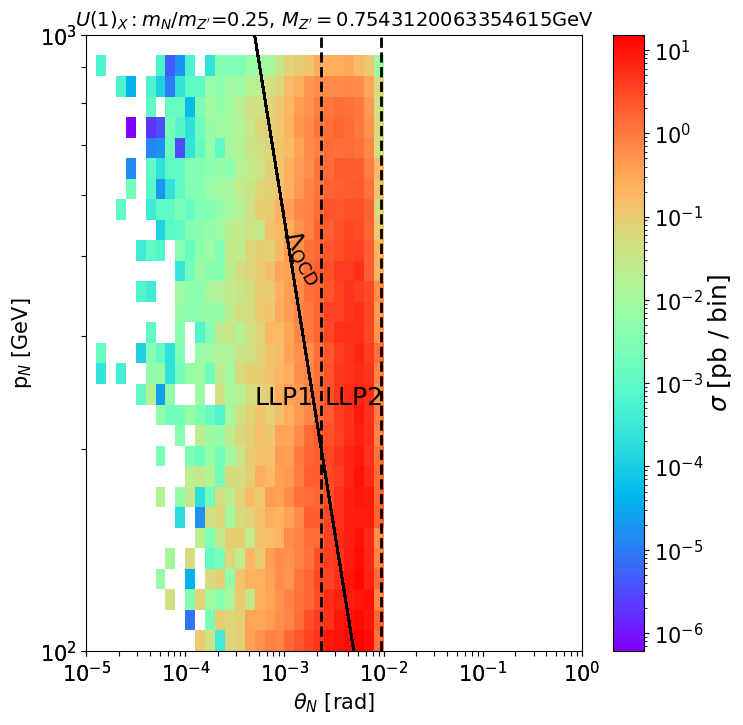

8.374979237037454e-05


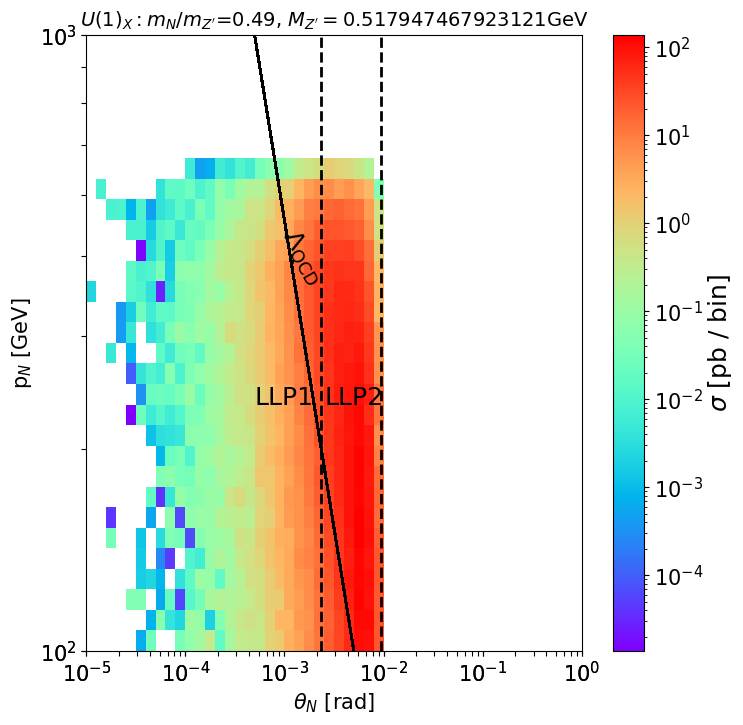

0.0005951703847734634


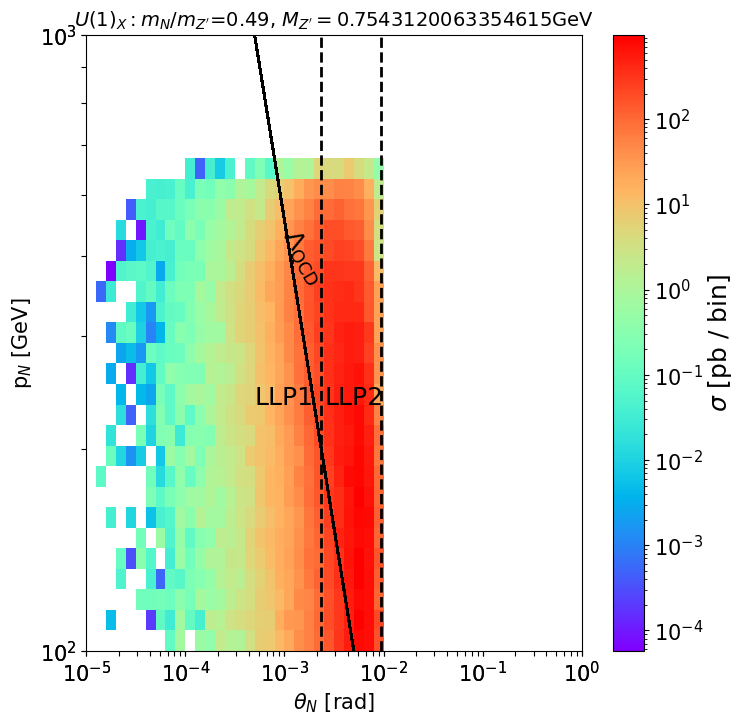

In [34]:
import RHN_decay as ndec
modelN = ndec.Calculate(1)
masses_all = np.logspace(-2, 0, 50)
masses = [masses_all[-8], masses_all[-4]]
mNs = [0.25, 0.49]
# distance, length = 1500, 400

for mN in mNs:
    name = "U1_X"
    modelD = darkcast.Model(name, Y1=mN, Y2=1000, Y3=1000, mZ=100)
        
    # Calculate branching fraction once per mass
    # bfrac_val = modelD.bfrac("Ne_Ne", mass, g=0.01, xH=0)
    for mass in masses:   
        
        pNs, wNs = [], []
        ctau = modelN.Nctau(mN*mass, 1e-3)
        for key in model.production.keys():
            dirname = "/home/souvik/codes/foresee-main/Models/DarkHiggs/model/LLP_spectra/"
            filename = f"{dirname}{energy}{unit}_{key}_{model.production[key]['type']}_m_{mass}.npy"
            p1s = foresee.decay_in_restframe_2body(1, mass, mass*mN, mass*mN, 1)[0]
            
            try:
                particles_llp, weights_llp = foresee.convert_list_to_momenta(
                    filename=filename, mass=mass, filetype="npy",
                    luminosity=30000, nsample=5, preselectioncut=None
                )
            except Exception:
                print(f"Warning: file {filename} not found")
                continue

            for p, w in zip(particles_llp, weights_llp):
                for p1 in p1s:
                    p1lab = p1.boost(-1.*p.boostvector)
                    p2lab = p - p1lab #p2.boost(-1.*p.boostvector)
                    # check if event passes
                    if not (foresee.event_passes(p1lab) or foresee.event_passes(p2lab)):
                        pNs.append(p1lab)
                        pNs.append(p1lab)
                        wNs.append(0)
                        wNs.append(0)
                
                    if foresee.event_passes(p1lab) and p1lab.pz>=100:
                        dbar1 = ctau*p1lab.p/(mass*mN)
                        prob_decay1 = np.exp(-(foresee.distance)/dbar1)-np.exp(-(foresee.distance+foresee.length)/dbar1)
                        pNs.append(p1lab)
                        wNs.append(w * prob_decay1) 
                        
                    if foresee.event_passes(p2lab) and p2lab.pz>=100:
                        dbar2 = ctau*p2lab.p/(mass*mN)
                        prob_decay2 = math.exp(-(foresee.distance)/dbar2)-math.exp(-(foresee.distance+foresee.length)/dbar2)
                        pNs.append(p2lab)
                        wNs.append(w * prob_decay2)
        print(sum(wNs)/1e8)                
        # 2. Guard against empty datasets
        if len(clean_weights) == 0 or sum(clean_weights) == 0:
            print(f"Skipping plot for mN={mN}, mass={mass}: No non-zero events generated.")
            continue


        foresee.convert_to_hist_list(pNs,wNs,luminosity=1/1000, do_plot=True, filename=None, cmap="rainbow",
                             do_return=False, prange=[[-5, 0, 50],[2, 3, 30]], vmin=None, vmax=None)

        plt.gca()
        plt.axvline(x=np.log10(10*np.sqrt(2)/1500), color='black', linestyle='--', linewidth=2)
        plt.axvline(x=np.log10(2.5*np.sqrt(2)/1500), color='black', linestyle='--', linewidth=2)

        ts = [p.pt/p.p for p in pNs]
        x = [np.log10(t) for t in ts]
        y = [np.log10(0.5)-i for i in x]
        plt.plot(x, y, color="black")
        plt.text(-3.3, 2.4, "LLP1", fontsize=18)
        plt.text(-2.6, 2.4, "LLP2", fontsize=18)
        plt.text(-3.1, 2.6, r"$\Lambda_\text{QCD}$", fontsize=18, rotation=-60)

        
        plt.xlabel(r"$\theta_{N}$ [rad]")
        plt.ylabel(r"p$_{N}$ [GeV]")
        
        plt.title(r"$U(1)_X: m_N/m_{Z'}$="+str(mN)+", $M_{Z'}=$"+str(mass)+"GeV", fontsize=14)
        plt.savefig("./"+str(mN)+"_"+str(mass)+"GeV.png")

        plt.show()

In [59]:
foresee = Foresee()
energy = "400"
unit = "GeV"
modelname = "DarkHiggs"
model = Model(modelname, path="/home/souvik/codes/foresee-main/Models/DarkHiggs/", mzp = 100, gBL = 0.01)

7440 7440


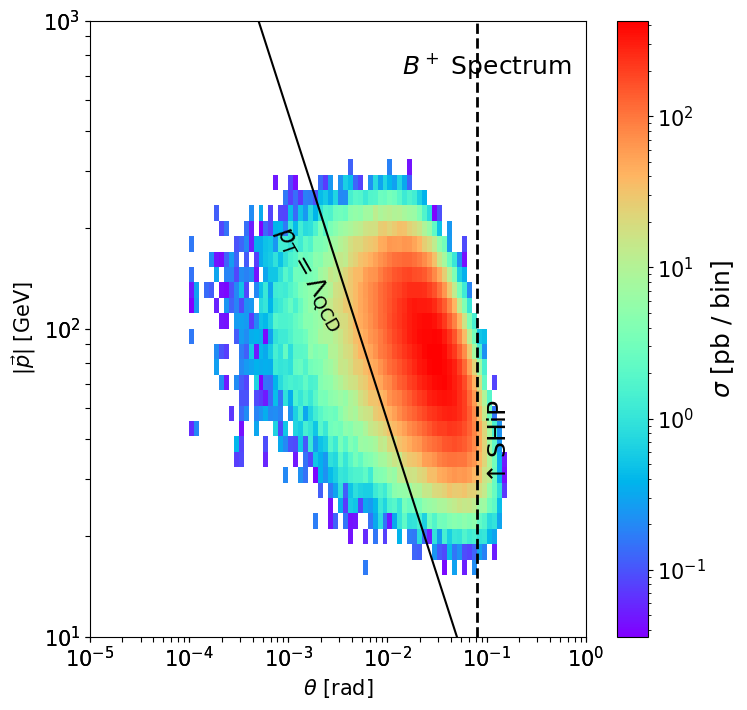

7440 7440


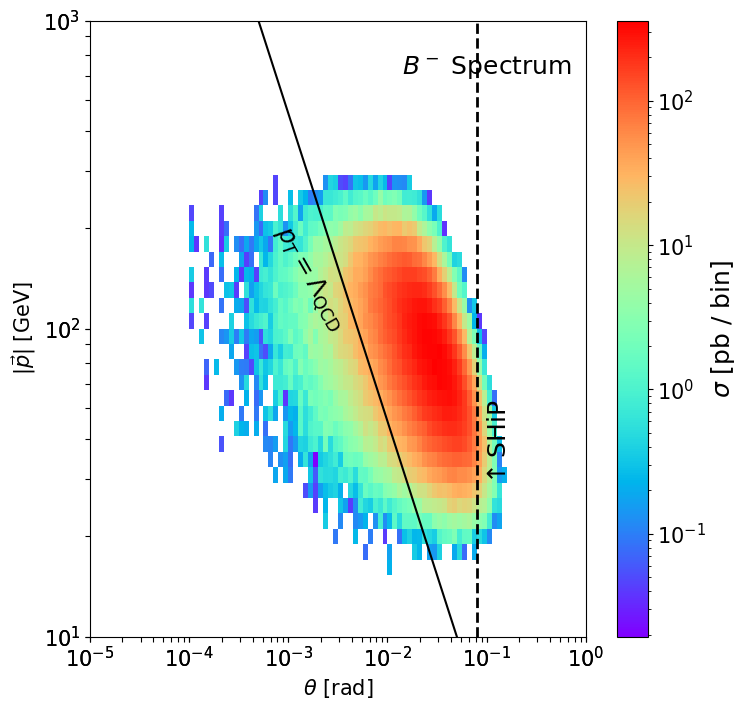

7440 7440


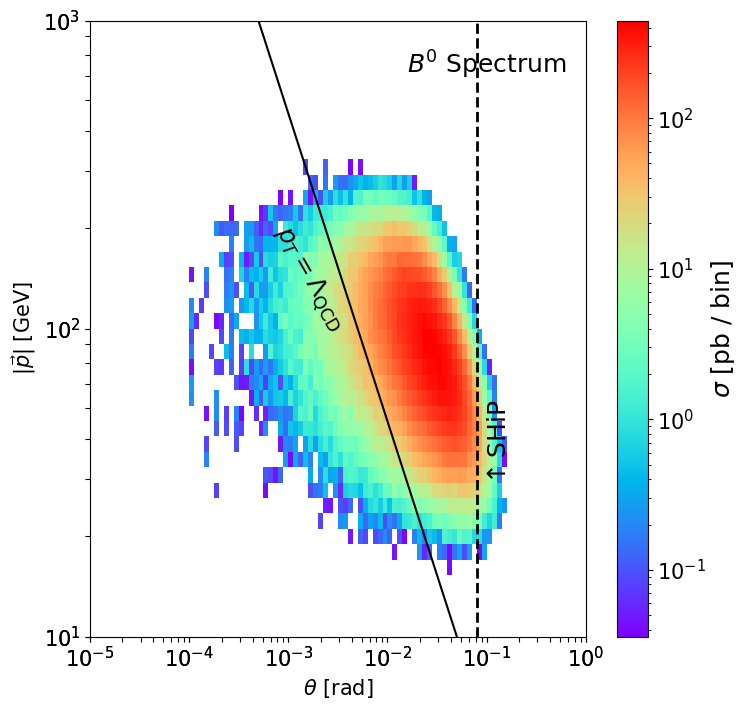

7440 7440


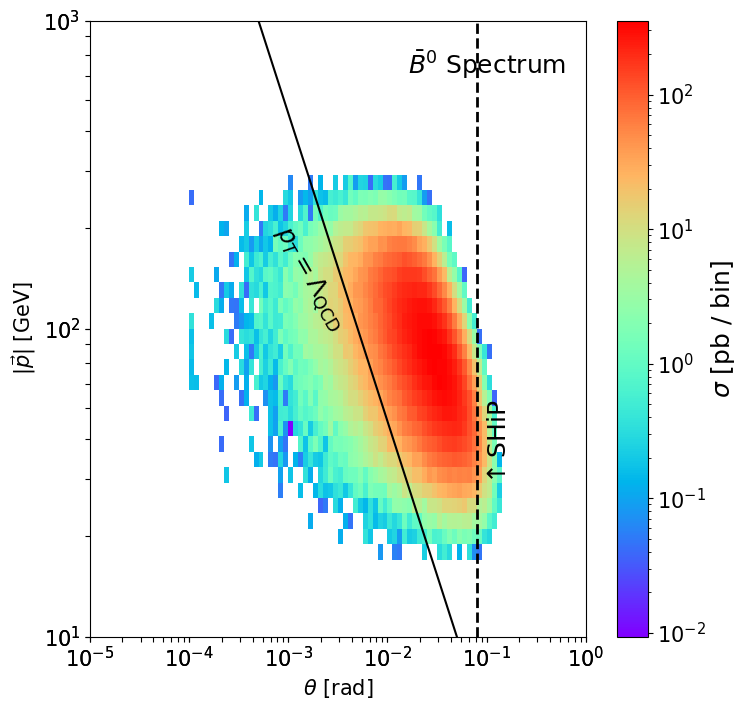

In [62]:
path = "/home/souvik/codes/foresee-main/files/hadrons/400GeV/PYANT/"
pids = ["511", "-511", "521", "-521"]
masses = {"511": 5.27961, "-511": 5.27961, "521": 5.27929, "-521": 5.27929}
names = {"511": r"$B^+$", "-511": r"$B^-$", "521": r"$B^0$", "-521": r"$\bar{B}^0$"}
for pid in pids:
    file = path+"PYANT_400GeV_"+pid+".txt"
    data = np.genfromtxt(file)
    ps , ws = foresee.convert_list_to_momenta(file,masses[pid], filetype="txt",luminosity=3000, nsample=1,preselectioncut=None, 
                                      nocuts=False, mincount=0, extend_to_low_pt_scale=None)
    foresee.convert_to_hist_list(ps,ws,luminosity=1/1000, do_plot=True, filename=None, cmap="rainbow",
                         do_return=False, prange=[[-5, 0, 100],[1, 3, 40]], vmin=None, vmax=None)
    
    plt.gca()
    plt.axvline(x=np.log10(np.sqrt(2.5**2+5**2)/70), color='black', linestyle='--', linewidth=2)

    ts = [p.pt/p.p for p in ps]
    x = [np.log10(t) for t in ts]
    y = [np.log10(0.5)-i for i in x]
    print(len(ps), len(ws))
    plt.plot(x, y, color="black")
    plt.text(-1, 1.5, r"$\uparrow$SHiP", fontsize=18, rotation=90)
    plt.title(names[pid]+" Spectrum", y=0.9, x=0.8)
    plt.text(-3.2, 2, r"$p_T=\Lambda_\text{QCD}$", fontsize=18, rotation=-60)
    
    plt.xlabel(r"$\theta$ [rad]")
    plt.ylabel(r"$|\vec{p}|$ [GeV]")
    plt.savefig("./"+pid+".png")
    plt.show()
    # foresee.get_spectrumplot(luminosity=3000, pid=pid, particle=r"$\Z'$--", generator="EPOSLHC", 
    #                      energy="14", prange=[[-6, 0, 120],[ 0, 5, 50]], vmin=0.5e12, vmax=0.5e16, mincount=0)

In [7]:
model.add_production_2bodydecay(
    pid0 = "511",
    pid1 = "130",
    br = "5.6 * coupling**2 * (1.-(mass/self.masses('pid0'))**2)**2",
    generator = 'PYANT',
    energy = energy,
    nsample = 50,
)

model.add_production_2bodydecay(
    pid0 = "-511",
    pid1 = "130",
    br = "5.6 * coupling**2 * (1.-(mass/self.masses('pid0'))**2)**2",
    generator = 'PYANT',
    energy = energy,
    nsample = 50,
)

model.add_production_2bodydecay(
    pid0 = "521",
    pid1 = "321",
    br = "5.6 * coupling**2 * (1.-(mass/self.masses('pid0'))**2)**2",
    generator = 'PYANT',
    energy = energy,
    nsample = 50,
)

model.add_production_2bodydecay(
    pid0 = "-521",
    pid1 = "321",
    br = "5.6 * coupling**2 * (1.-(mass/self.masses('pid0'))**2)**2",
    generator = 'PYANT',
    energy = energy,
    nsample = 50,
)

In [8]:
model.add_production_2bodydecay(
    label= "511*",
    pid0 = "511",
    pid1 = "313",
    br = "5.6 * coupling**2 * (1.-(mass/self.masses('pid0'))**2)**2",
    generator = 'PYANT',
    energy = energy,
    nsample = 50,
)

model.add_production_2bodydecay(
    label= "-511*",
    pid0 = "-511",
    pid1 = "-313",
    br = "5.6 * coupling**2 * (1.-(mass/self.masses('pid0'))**2)**2",
    generator = 'PYANT',
    energy = energy,
    nsample = 50,
)

model.add_production_2bodydecay(
    label= "521*",
    pid0 = "521",
    pid1 = "323",
    br = "5.6 * coupling**2 * (1.-(mass/self.masses('pid0'))**2)**2",
    generator = 'PYANT',
    energy = energy,
    nsample = 50,
)

model.add_production_2bodydecay(
    label= "-521*",
    pid0 = "-521",
    pid1 = "-323",
    br = "5.6 * coupling**2 * (1.-(mass/self.masses('pid0'))**2)**2",
    generator = 'PYANT',
    energy = energy,
    nsample = 50,
)

In [9]:
model.add_production_3bodydecay(
    label= "511_di",
    pid0 = "511",
    pid1 = "130",
    pid2 = "0",
    br = "6.76e-5*(self.model.lambda_mix(coupling, mass))**2*(self.masses('5')/4.5)**3*np.sqrt(1-4*mass**2/q**2)*(1-q**2/self.masses('5')**2)**2",
    generator = 'PYANT',
    energy = energy,
    nsample = 50,
    scaling = 0, 
)

model.add_production_3bodydecay(
    label= "-511_di",
    pid0 = "-511",
    pid1 = "130",
    pid2 = "0",
    br = "6.76e-5*(self.model.lambda_mix(coupling, mass))**2*(self.masses('5')/4.5)**3*np.sqrt(1-4*mass**2/q**2)*(1-q**2/self.masses('5')**2)**2",
    generator = 'PYANT',
    energy = energy,
    nsample = 50,
    scaling = 0, 
)

model.add_production_3bodydecay(
    label= "521_di",
    pid0 = "521",
    pid1 = "321",
    pid2 = "0",
    br = "6.76e-5*(self.model.lambda_mix(coupling, mass))**2*(self.masses('5')/4.5)**3*np.sqrt(1-4*mass**2/q**2)*(1-q**2/self.masses('5')**2)**2",
    generator = 'PYANT',
    energy = energy,
    nsample = 50,
    scaling = 0, 
)

model.add_production_3bodydecay(
    label= "-521_di",
    pid0 = "-521",
    pid1 = "321",
    pid2 = "0",
    br = "6.76e-5*(self.model.lambda_mix(coupling, mass))**2*(self.masses('5')/4.5)**3*np.sqrt(1-4*mass**2/q**2)*(1-q**2/self.masses('5')**2)**2",
    generator = 'PYANT',
    energy = energy,
    nsample = 50,
    scaling = 0, 
)

In [10]:
model.add_production_3bodydecay(
    label= "511_di",
    pid0 = "511",
    pid1 = "313",
    pid2 = "0",
    br = "6.76e-5*(self.model.lambda_mix(coupling, mass))**2*(self.masses('5')/4.5)**3*np.sqrt(1-4*mass**2/q**2)*(1-q**2/self.masses('5')**2)**2",
    generator = 'PYANT',
    energy = energy,
    nsample = 50,
    scaling = 0, 
)

model.add_production_3bodydecay(
    label= "-511_di",
    pid0 = "-511",
    pid1 = "313",
    pid2 = "0",
    br = "6.76e-5*(self.model.lambda_mix(coupling, mass))**2*(self.masses('5')/4.5)**3*np.sqrt(1-4*mass**2/q**2)*(1-q**2/self.masses('5')**2)**2",
    generator = 'PYANT',
    energy = energy,
    nsample = 50,
    scaling = 0, 
)

model.add_production_3bodydecay(
    label= "521_di",
    pid0 = "521",
    pid1 = "321",
    pid2 = "0",
    br = "6.76e-5*(self.model.lambda_mix(coupling, mass))**2*(self.masses('5')/4.5)**3*np.sqrt(1-4*mass**2/q**2)*(1-q**2/self.masses('5')**2)**2",
    generator = 'PYANT',
    energy = energy,
    nsample = 50,
    scaling = 0, 
)

model.add_production_3bodydecay(
    label= "-521_di",
    pid0 = "-521",
    pid1 = "321",
    pid2 = "0",
    br = "6.76e-5*(self.model.lambda_mix(coupling, mass))**2*(self.masses('5')/4.5)**3*np.sqrt(1-4*mass**2/q**2)*(1-q**2/self.masses('5')**2)**2",
    generator = 'PYANT',
    energy = energy,
    nsample = 50,
    scaling = 0, 
)

In [11]:
foresee.set_model(model=model)

In [12]:
# mass = 0.1
# model1 = {-2: "U1_X_2n", 2: "U1_X_2p"}
# xHs = [-2, 2]
# for xH in xHs:
#     foresee.get_llp_spectrum(mass=mass, coupling=1, luminosity=1/1000, mincount=0, cmap="rainbow",
#                                 do_plot=True, stat_cuts=None, save_file=False, prange=[[-5, 0, 100],[0, 3.5, 70]])
#         # r = foresee.ratio(mass, model1[xH], "B-L_boson", key, 1/3, 1/3, 1/3)
#         # for w,p in zip(ws, ps):
#         #     Ps.append(p)
#         #     Ws.append(w*r)
        
#     # foresee.convert_to_hist_list(Ps,Ws,luminosity=1/1000, do_plot=True, filename=None, cmap="rainbow",
#     #                      do_return=False, prange=[[-5, 0, 100],[0, 3.5, 70]], vmin=None, vmax=None)
    
#     plt.axvline(np.log(1/630), color='black', linestyle='--', linewidth=4)

#     plt.title(r"$M_{Z'}=$"+str(mass)+" GeV \n $x_H=$"+str(xH), y=0.9, x=0.8)

#     plt.gca()
#     plt.axvline(x=np.log10(1/630), color='black', linestyle='--', linewidth=2)

#     ts = 10**np.linspace(-5, 0, 100)
#     x = [np.log10(t) for t in ts]
#     y = [np.log10(0.5)-i for i in x]
#     plt.plot(x, y, color="black")
#     plt.text(-2.7, 0.5, r"$\uparrow$FASER2", fontsize=18, rotation=90)
#     plt.text(-1.8, 1, r"$p_T=\Lambda_\text{QCD}$", fontsize=18, rotation=-60)
#     plt.xlabel(r"$\theta_{Z^\prime}$ [rad]")
#     plt.ylabel(r"p$_{Z^\prime}$ [GeV]")
#     plt.savefig(r"/home/souvik/codes/FORESEE_fig/spectrum/Zp_"+str(xH)+".png")


In [13]:
foresee.set_detector(
    distance=70, 
    selection="abs(x.x)<2.5 and abs(x.y)<5", 
    length=50, unit=unit,
    luminosity=6e20/1.085e15, name="U1_X",
)

0.040767452481281184


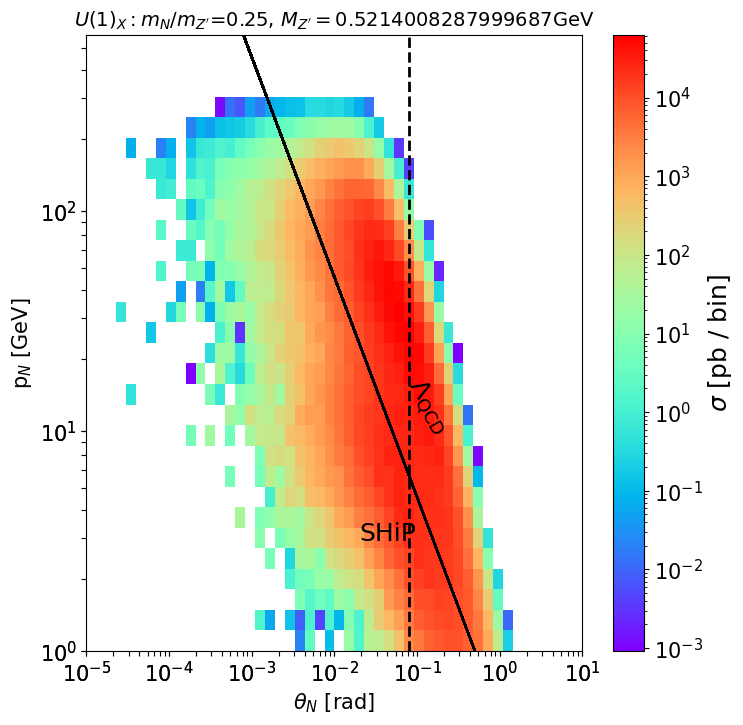

0.08085913403561318


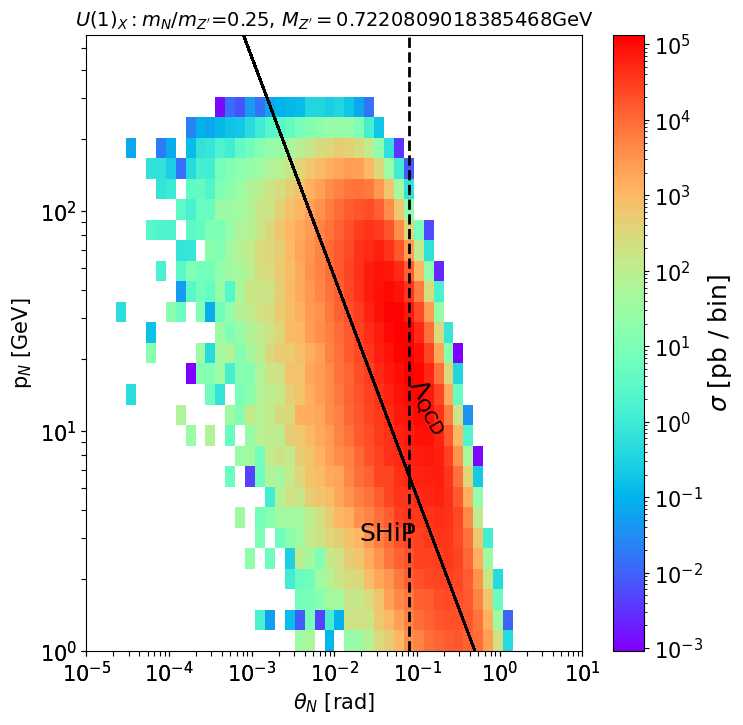

0.040767452481281184


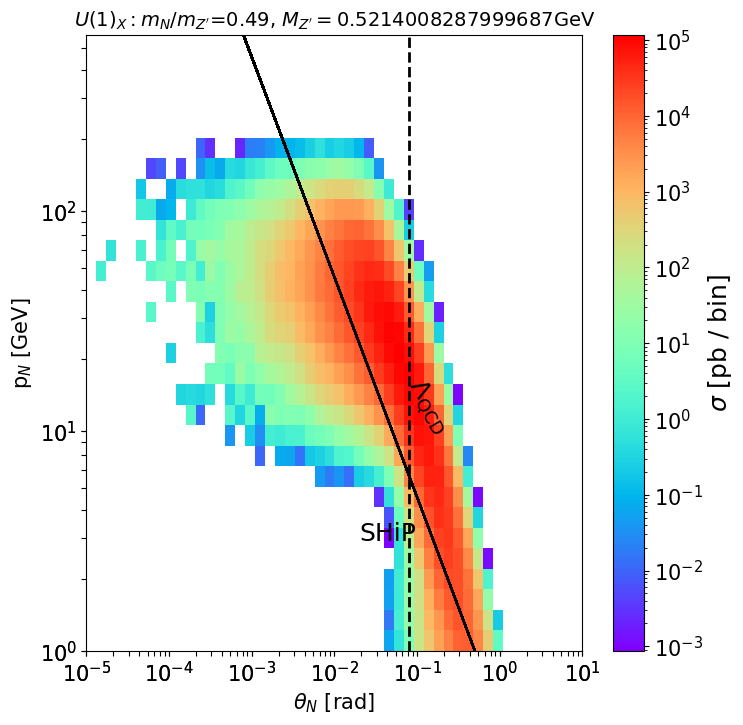

0.08085913403561318


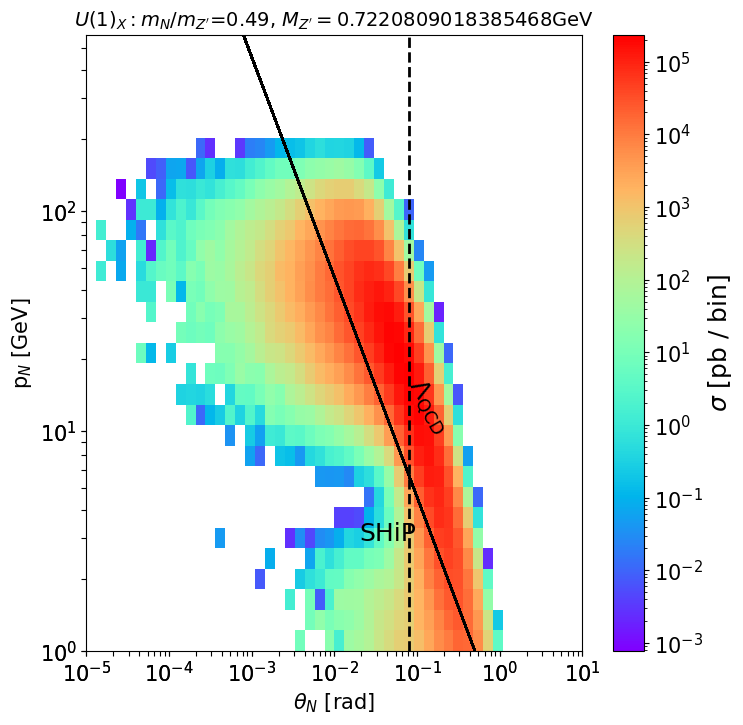

In [28]:
masses_all = np.logspace(-2,0,100)
masses = [masses_all[-15], masses_all[-8]]
mNs = [0.25, 0.49]

for mN in mNs:
    name = "U1_X"
    modelD = darkcast.Model(name, Y1=mN, Y2=1000, Y3=1000, mZ=100)
    pNs, wNs = [], []
        
    # Calculate branching fraction once per mass
    # bfrac_val = modelD.bfrac("Ne_Ne", mass, g=0.01, xH=0)
    for mass in masses:   
        for key in model.production.keys():
            dirname = "/home/souvik/codes/foresee-main/Models/DarkHiggs/model/LLP_spectra/"
            filename = f"{dirname}{energy}{unit}_{key}_{model.production[key]['type']}_m_{mass}.npy"
            p1s = foresee.decay_in_restframe_2body(1, mass, mass*mN, mass*mN, 1)[0]
            
            try:
                particles_llp, weights_llp = foresee.convert_list_to_momenta(
                    filename=filename, mass=mass, filetype="npy",
                    luminosity=1, nsample=5, preselectioncut=None
                )
            except Exception:
                print(f"Warning: file {filename} not found")
                continue

            for p, w in zip(particles_llp, weights_llp):
                if w == 0: 
                    continue
                # pNs.append(p)
                # wNs.append(w)
                for p1 in p1s:
                    p1lab = p1.boost(-1. * p.boostvector)
                    pNs.append(p1lab)
                    wNs.append(w)
                    
                    p2lab = p - p1lab
                    pNs.append(p2lab)
                    wNs.append(w)
        print(sum(wNs)/1e8)
        # 1. Extract 1D kinematic variables
        x_phi = []
        y_mag = []
        clean_weights = []
        for p, w in zip(pNs, wNs):
            if w > 0:
                phi = np.arccos(p.pz/ p.p) 
                mag = p.p 
                x_phi.append(phi)
                y_mag.append(mag)
                clean_weights.append(w)

        # 2. Guard against empty datasets
        if len(clean_weights) == 0 or sum(clean_weights) == 0:
            print(f"Skipping plot for mN={mN}, mass={mass}: No non-zero events generated.")
            continue


        foresee.convert_to_hist_list(pNs,wNs,luminosity=1/1000, do_plot=True, filename=None, cmap="rainbow",
                             do_return=False, prange=[[-5, 1, 50],[0, 2.8, 30]], vmin=None, vmax=None)

        plt.gca()
        plt.axvline(x=np.log10(np.sqrt(2.5**2+5**2)/70), color='black', linestyle='--', linewidth=2)

        ts = [p.pt/p.p for p in pNs]
        x = [np.log10(t) for t in ts]
        y = [np.log10(0.5)-i for i in x]
        plt.plot(x, y, color="black")
        plt.text(-1.7, 0.5, "SHiP", fontsize=18)
        plt.text(-1.2, 1, r"$\Lambda_\text{QCD}$", fontsize=18, rotation=-60)

        
        plt.xlabel(r"$\theta_{N}$ [rad]")
        plt.ylabel(r"p$_{N}$ [GeV]")
        
        plt.title(r"$U(1)_X: m_N/m_{Z'}$="+str(mN)+", $M_{Z'}=$"+str(mass)+"GeV", fontsize=14)
        plt.savefig("./"+str(mN)+"_"+str(mass)+"GeV.png")

        plt.show()

2.05168147417714e-11
6.641295590940582e-11
1.7704907466622806e-10
4.954859963067998e-10


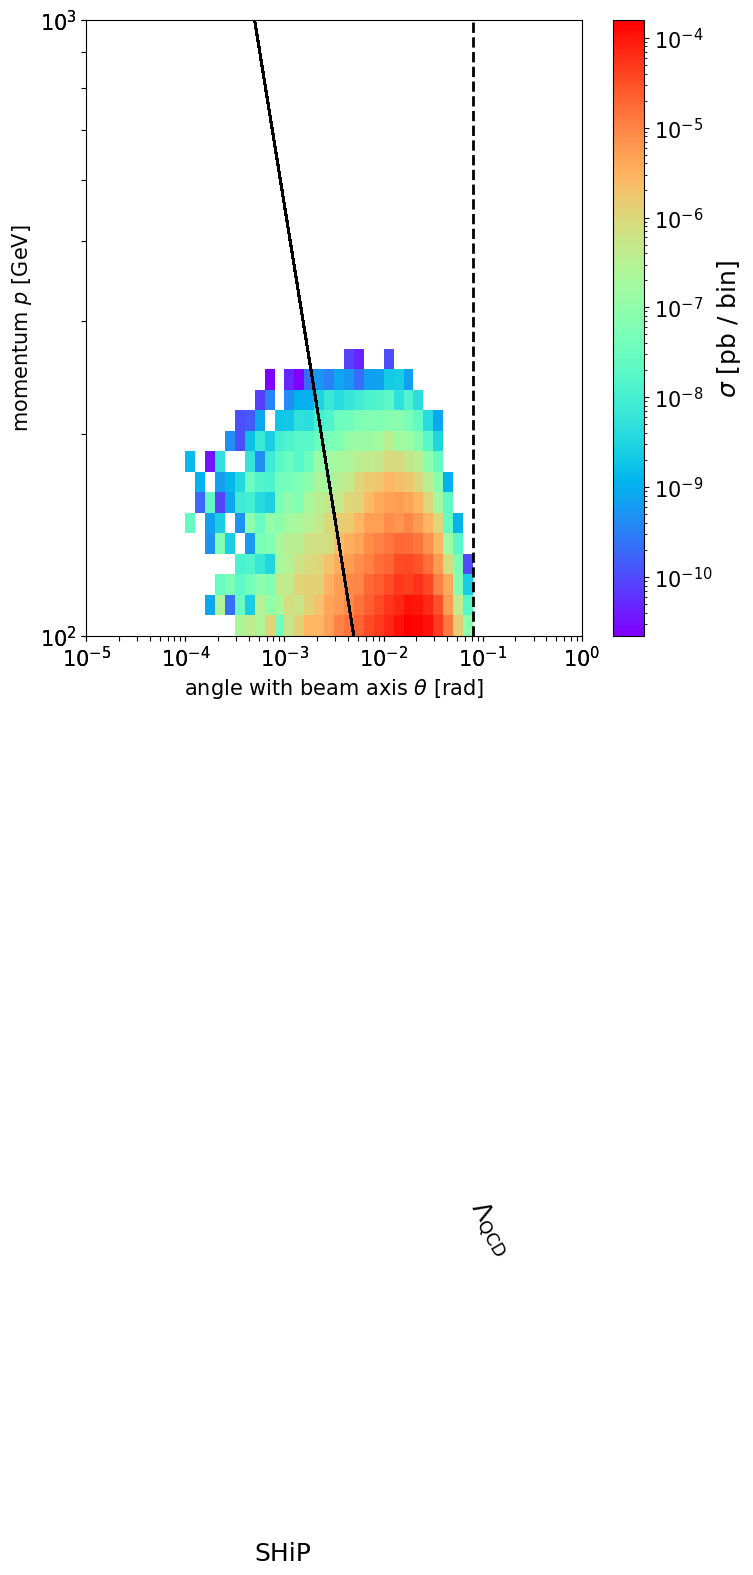

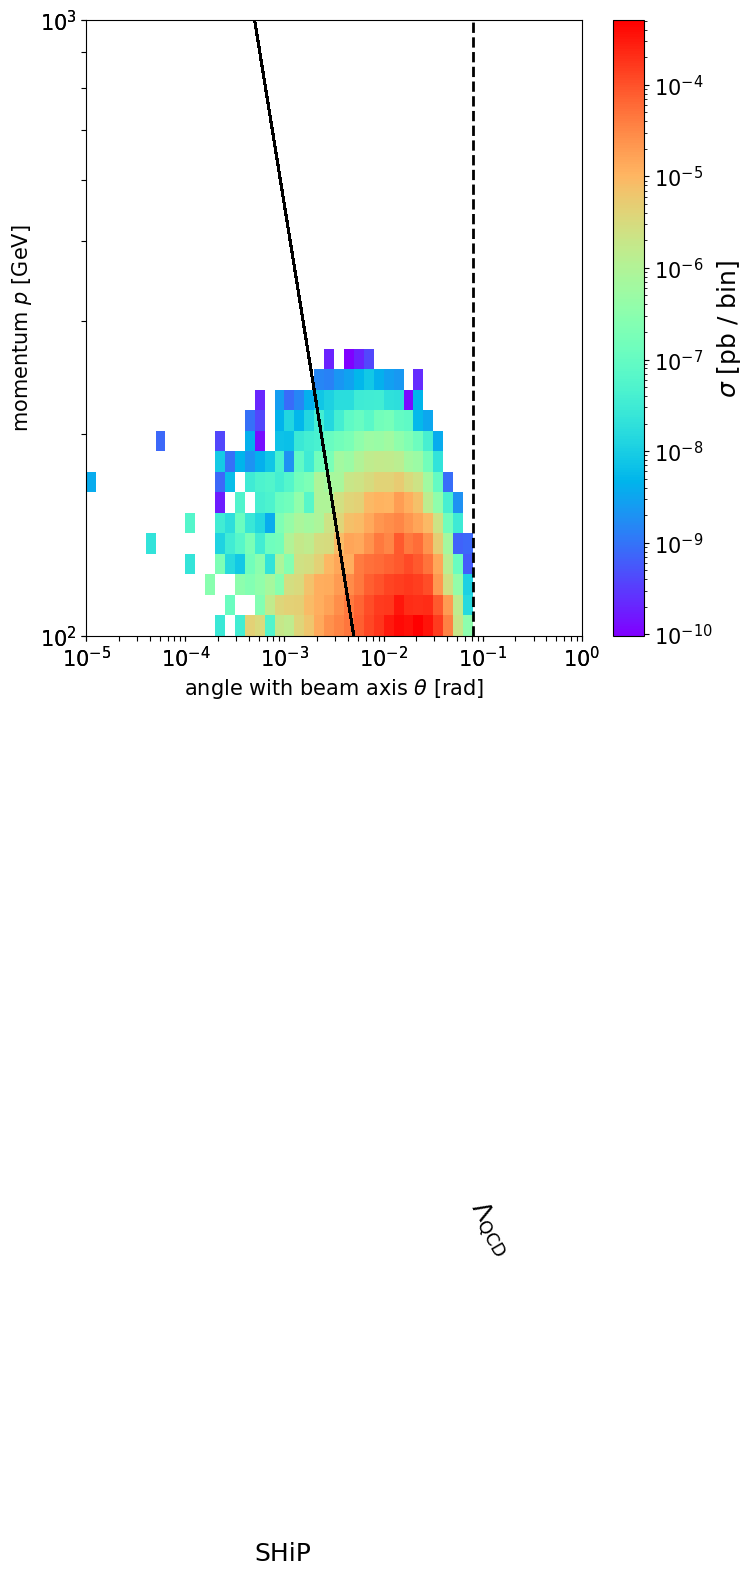

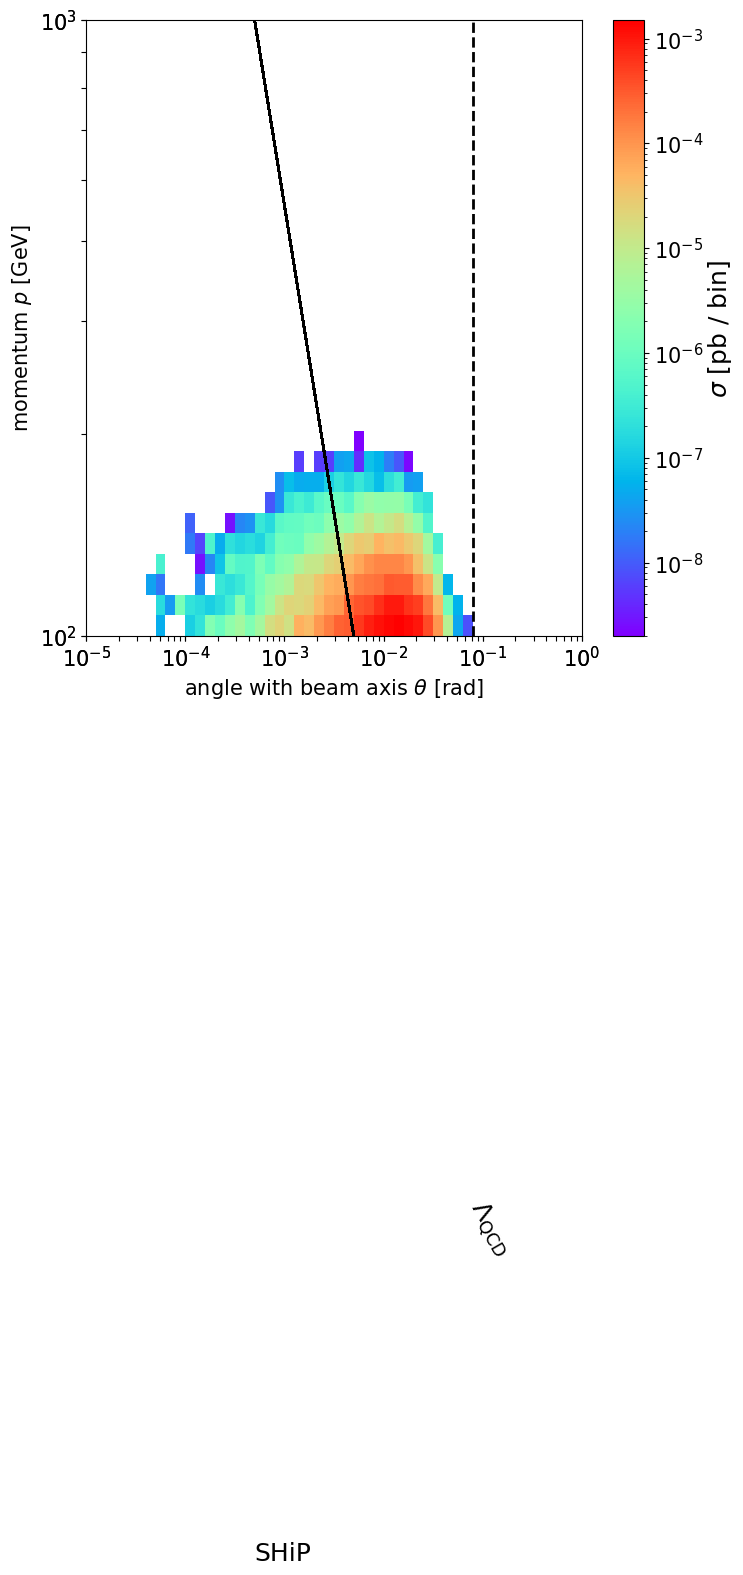

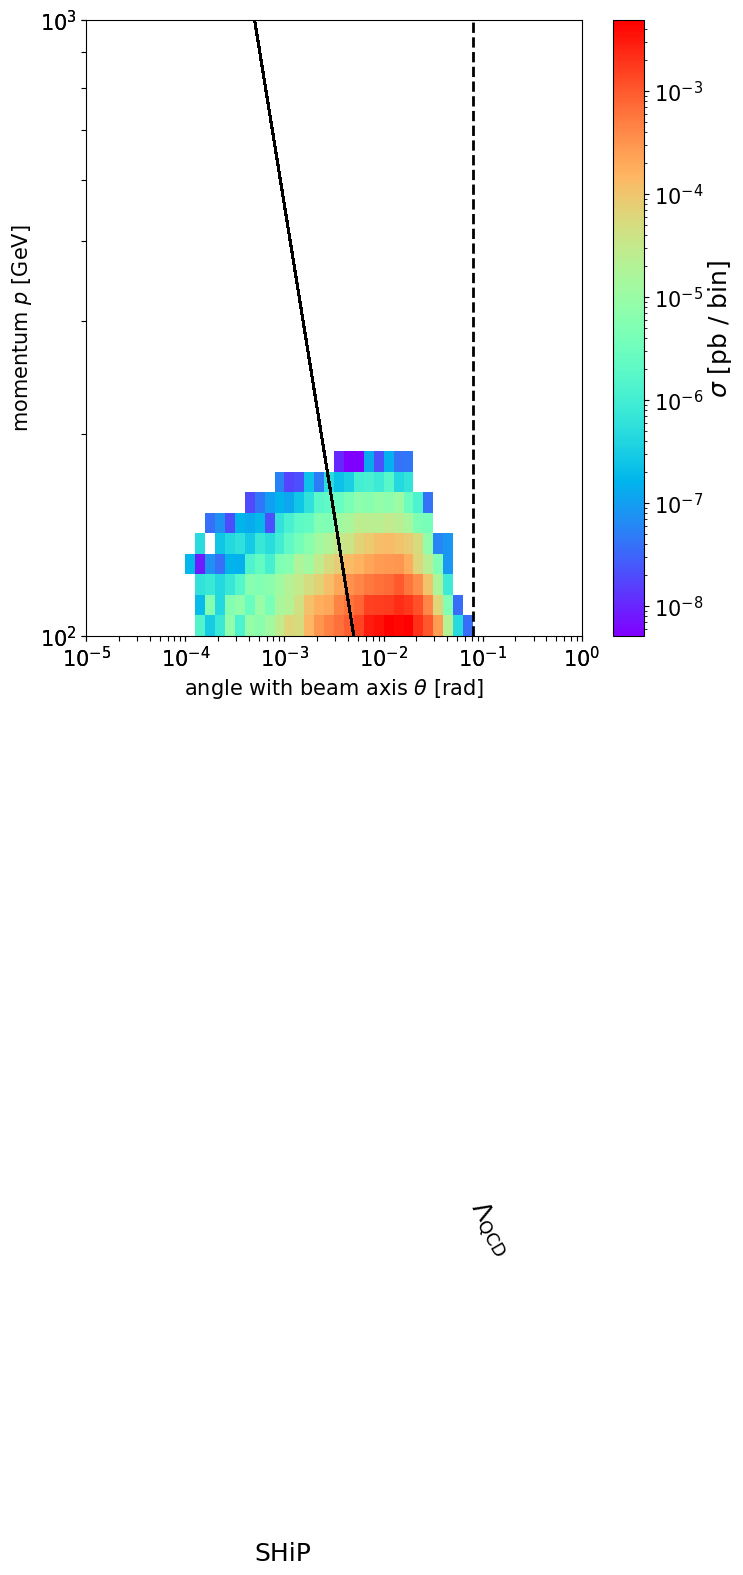

In [20]:
import RHN_decay as ndec
modelN = ndec.Calculate(1)
masses_all = np.logspace(-2, 0, 100)
masses = [masses_all[-8], masses_all[-4]]
mNs = [0.25, 0.49]
# distance, length = 1500, 400

for mN in mNs:
    name = "U1_X"
    modelD = darkcast.Model(name, Y1=mN, Y2=1000, Y3=1000, mZ=100)
        
    # Calculate branching fraction once per mass
    # bfrac_val = modelD.bfrac("Ne_Ne", mass, g=0.01, xH=0)
    for mass in masses:   
        
        pNs, wNs = [], []
        ctau = modelN.Nctau(mN*mass, 1e-3)
        for key in model.production.keys():
            dirname = "/home/souvik/codes/foresee-main/Models/DarkHiggs/model/LLP_spectra/"
            filename = f"{dirname}{energy}{unit}_{key}_{model.production[key]['type']}_m_{mass}.npy"
            p1s = foresee.decay_in_restframe_2body(1, mass, mass*mN, mass*mN, 1)[0]
            
            try:
                particles_llp, weights_llp = foresee.convert_list_to_momenta(
                    filename=filename, mass=mass, filetype="npy",
                    luminosity=30000, nsample=5, preselectioncut=None
                )
            except Exception:
                print(f"Warning: file {filename} not found")
                continue

            for p, w in zip(particles_llp, weights_llp):
                for p1 in p1s:
                    p1lab = p1.boost(-1.*p.boostvector)
                    p2lab = p - p1lab #p2.boost(-1.*p.boostvector)
                    # check if event passes
                    if not (foresee.event_passes(p1lab) or foresee.event_passes(p2lab)):
                        pNs.append(p1lab)
                        pNs.append(p1lab)
                        wNs.append(0)
                        wNs.append(0)
                
                    if foresee.event_passes(p1lab) and p1lab.pz>=100:
                        dbar1 = ctau*p1lab.p/(mass*mN)
                        prob_decay1 = np.exp(-(foresee.distance)/dbar1)-np.exp(-(foresee.distance+foresee.length)/dbar1)
                        pNs.append(p1lab)
                        wNs.append(w * prob_decay1) 
                        
                    if foresee.event_passes(p2lab) and p2lab.pz>=100:
                        dbar2 = ctau*p2lab.p/(mass*mN)
                        prob_decay2 = math.exp(-(foresee.distance)/dbar2)-math.exp(-(foresee.distance+foresee.length)/dbar2)
                        pNs.append(p2lab)
                        wNs.append(w * prob_decay2)
        print(sum(wNs)/1e8)                
        # 2. Guard against empty datasets
        if len(clean_weights) == 0 or sum(clean_weights) == 0:
            print(f"Skipping plot for mN={mN}, mass={mass}: No non-zero events generated.")
            continue


        foresee.convert_to_hist_list(pNs,wNs,luminosity=1/1000, do_plot=True, filename=None, cmap="rainbow",
                             do_return=False, prange=[[-5, 0, 50],[2, 3, 30]], vmin=None, vmax=None)

        plt.gca()
        plt.axvline(x=np.log10(np.sqrt(2.5**2+5**2)/70), color='black', linestyle='--', linewidth=2)

        ts = [p.pt/p.p for p in pNs]
        x = [np.log10(t) for t in ts]
        y = [np.log10(0.5)-i for i in x]
        plt.plot(x, y, color="black")
        plt.text(-3.3, 0.5, "SHiP", fontsize=18)
        plt.text(-1.2, 1, r"$\Lambda_\text{QCD}$", fontsize=18, rotation=-60)